In [ ]:
from utils import demo, print_tree, show_graph, show_run

from url4.dag import run

The cells below run offline. `StaticIOLayer` answers each fetch from a dict, so no network is needed.
A real node works the same way: pass `run()` or `show_run()` an IO layer that talks HTTP (the default), and the expression does not change.

In [ ]:
from url4.io.static import StaticIOLayer

# Offline stand-in for the live host: the same run() call, answered from a dict.
host = StaticIOLayer({"https://syfthub.openmined.org": "SyftHub is a catalog of url4 nodes."})
await run("https://syfthub.openmined.org!Summarize This", host)

In [ ]:
await show_run("https://syfthub.openmined.org!Summarize This", host)

In [6]:
# name=… binds a source; $article / $style inject it. Dashed edges = the $context flow.
expr = (
    "(article=https://news.example.com/ai-act, style='plain English')"
    "!'Summarize $article in $style'"
)
await run(expr, demo)

"Summarize EU lawmakers gave final approval to the AI Act, the first broad law governing artificial intelligence. It ranks systems by risk, bans social scoring and manipulative uses, and requires transparency and human oversight for high-risk uses in hiring, credit, and healthcare. Most rules phase in over two years. in 'plain English'"

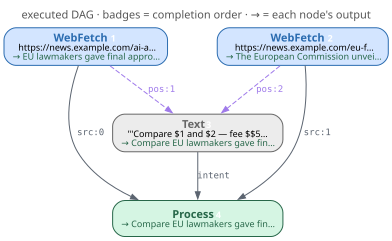

#,node,inputs,output
1,WebFetch https://news.example.com/ai-a…,—,EU lawmakers gave final approval to the…
2,WebFetch https://news.example.com/eu-f…,—,The European Commission unveiled a EUR …
3,"Text ""'Compare $1 and $2 — fee $$5…","pos:1=EU lawmakers gave…, pos:2=The European Comm…",Compare EU lawmakers gave final approva…
4,Process,"src:0=EU lawmakers gave…, src:1=The European Comm…, intent=Compare EU lawmak…",Compare EU lawmakers gave final approva…


In [7]:
# $1..$N reference sources by position; $$ is a literal $.
expr = (
    "(https://news.example.com/ai-act, https://news.example.com/eu-funding)"
    "!'Compare $1 and $2 — fee $$5'"
)
await show_run(expr, demo)

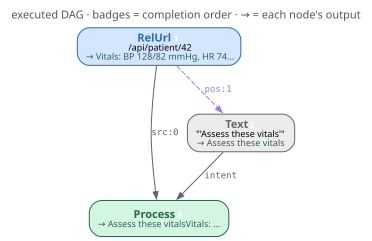

#,node,inputs,output
1,RelUrl /api/patient/42,—,"Vitals: BP 128/82 mmHg, HR 74 bpm, Temp…"
2,"Text ""'Assess these vitals'""",pos:1=Vitals: BP 128/82…,Assess these vitals
3,Process,"src:0=Vitals: BP 128/82…, intent=Assess these vita…",Assess these vitals Vitals: BP 128/82 …


In [8]:
# A /path source is fetched relative to the node (here, an internal patient API).
await show_run("/api/patient/42!'Assess these vitals'", demo)

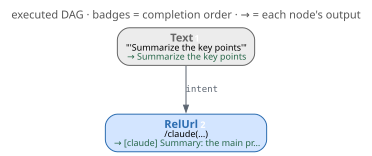

#,node,inputs,output
1,"Text ""'Summarize the key points'""",—,Summarize the key points
2,RelUrl /claude(…),intent=Summarize the key…,"[claude] Summary: the main provisions, …"


In [10]:
# /path(context)!intent is a relative EXPRESSION: fetched from the localhost
# /claude route as /claude?q=(context)!intent (a RelUrl node — no separate "call").
await show_run("/claude(https://news.example.com/ai-act)!'Summarize the key points'", demo)

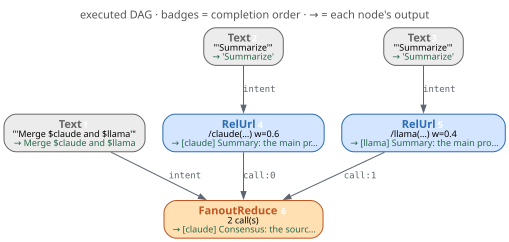

#,node,inputs,output
1,"Text ""'Merge $claude and $llama'""",—,Merge $claude and $llama
2,"Text ""'Summarize'""",—,'Summarize'
3,"Text ""'Summarize'""",—,'Summarize'
4,RelUrl /claude(…) w=0.6,intent='Summarize',"[claude] Summary: the main provisions, …"
5,RelUrl /llama(…) w=0.4,intent='Summarize',"[llama] Summary: the main provisions, o…"
6,FanoutReduce 2 call(s),"intent=Merge $claude and…, call:0=[claude] Summary:…, call:1=[llama] Summary: …",[claude] Consensus: the sources broadly…


In [11]:
# Weighted ensemble: two model calls run in parallel; one FanoutReduce node merges them.
expr = (
    "(claude:0.6:/claude(https://news.example.com/ai-act)!'Summarize',"
    "llama:0.4:/llama(https://news.example.com/ai-act)!'Summarize')"
    "!'Merge $claude and $llama'"
)
await show_run(expr, demo)

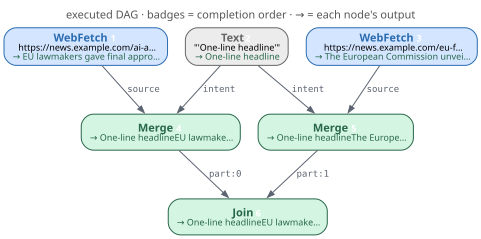

#,node,inputs,output
1,WebFetch https://news.example.com/ai-a…,—,EU lawmakers gave final approval to the…
2,"Text ""'One-line headline'""",—,One-line headline
3,WebFetch https://news.example.com/eu-f…,—,The European Commission unveiled a EUR …
4,Merge,"source=EU lawmakers gave…, intent=One-line headline",One-line headline EU lawmakers gave fi…
5,Merge,"source=The European Comm…, intent=One-line headline",One-line headline The European Commiss…
6,Join,"part:0=One-line headline…, part:1=One-line headline…",One-line headline EU lawmakers gave fi…


In [12]:
# !* applies the same intent to each source independently (note the single shared Text node).
expr = "(https://news.example.com/ai-act, https://news.example.com/eu-funding)!*'One-line headline'"
await show_run(expr, demo)

In [ ]:
# collection*(body)!intent runs the body once per row; $item.field binds the row.
# Map expands at runtime.
expr = (
    "https://data.example.com/support-tickets*(/claude($item.question)!'Answer')"
    "!'Answer each ticket'"
)
await show_run(expr, demo)

In [14]:
await run(expr, demo)

'[claude] Re: How do I reset my password? — follow the documented steps; escalate if needed.\n[claude] Re: Why was my card declined at checkout? — follow the documented steps; escalate if needed.\n[claude] Re: Can I export my data as CSV? — follow the documented steps; escalate if needed.'

In [ ]:
# on_error=collect turns a failing row (missing $item.question) into an {"error": …} output
# only with strict_fields=True.
expr = (
    "https://data.example.com/tickets-messy*(/claude($item.question)!'Answer')!'Answer each ticket'"
    ";iteration.on_error=collect"
)
await show_run(expr, demo)

In [ ]:
# The `*` operator iterates a collection: `collection*(body)!intent` runs the
# body once per item (spec §5.3). Here each paper title is summarized via /claude.
await show_run(
    "https://data.example.com/reading-list*(/claude($item)!'Summarize this paper in one line')"
    "!'Summarize each paper'",
    demo,
)

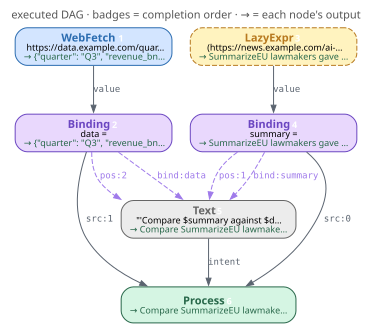

#,node,inputs,output
1,WebFetch https://data.example.com/quar…,—,"{""quarter"": ""Q3"", ""revenue_bn"": 4.2, ""y…"
2,Binding data =,"value={""quarter"": ""Q3"",…","{""quarter"": ""Q3"", ""revenue_bn"": 4.2, ""y…"
3,LazyExpr (https://news.example.com/ai-…,—,Summarize EU lawmakers gave final appr…
4,Binding summary =,value=Summarize EU law…,Summarize EU lawmakers gave final appr…
5,"Text ""'Compare $summary against $d…","pos:1=Summarize EU law…, pos:2={""quarter"": ""Q3"",…, bind:summary=Summarize EU law…, bind:data={""quarter"": ""Q3"",…",Compare Summarize EU lawmakers gave fi…
6,Process,"src:0=Summarize EU law…, src:1={""quarter"": ""Q3"",…, intent=Compare Summarize…",Compare Summarize EU lawmakers gave fi…


In [17]:
# A nested (…)!… is a LazyExpr node — compiled only when execution reaches it.
expr = (
    "(summary=(https://news.example.com/ai-act)!'Summarize',"
    " data=https://data.example.com/quarterly.json)"
    "!'Compare $summary against $data'"
)
await show_run(expr, demo)

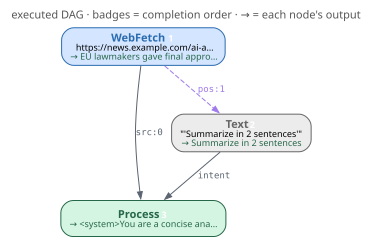

#,node,inputs,output
1,WebFetch https://news.example.com/ai-a…,—,EU lawmakers gave final approval to the…
2,"Text ""'Summarize in 2 sentences'""",pos:1=EU lawmakers gave…,Summarize in 2 sentences
3,Process,"src:0=EU lawmakers gave…, intent=Summarize in 2 se…",<system>You are a concise analyst.</sys…


In [18]:
# process(sources, intent, scope) is the overridable merge step — here, a chat-style template.
async def as_chat(sources, intent, scope):
    return f"<system>You are a concise analyst.</system>\n<user>{intent}\n\n{sources}</user>"


expr = "(https://news.example.com/ai-act)!'Summarize in 2 sentences'"
await show_run(expr, demo, process=as_chat)

In [ ]:
# show_graph renders STRUCTURE without executing — nested groups stay LazyExpr.
expr = (
    "(article=https://news.example.com/ai-act,"
    " claude:0.6:/claude($article)!'Summarize',"
    " (draft, notes)!'Combine')"
    "!'Brief: $article'"
)
show_graph(expr)

In [ ]:
# print_tree: zero-dependency ASCII view (works even without the Graphviz binary).
expr = (
    "(https://data.example.com/support-tickets*(/claude($item.question)!'Answer')"
    "!'Answer each ticket')"
    "!'Summarize resolutions'"
)
print_tree(expr)

In [ ]:
# Each failure mode is a typed exception (run() surfaces them; show_run would re-raise).
# strict_fields=True makes a missing field a ScopeError instead of an empty substitution.
messy = (
    "https://data.example.com/tickets-messy*(/claude($item.question)!'Answer')"
    "!'Answer each ticket';iteration.on_error=fail"
)
cases = [
    "(unclosed",  # ParseError  — malformed grammar
    messy,  # ScopeError  — row missing $item.question
    "https://nowhere.example.com/x!'go'",  # ResolutionError — unknown URL
    "https://data.example.com/webpage*($item)!x",  # CollectionError — HTML, not data
]
for expr in cases:
    try:
        await run(expr, demo, strict_fields=True)
    except Exception as e:
        print(f"{type(e).__name__:16}: {str(e).splitlines()[0]}")